In [54]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import tensorflow as tf
from pathlib import Path
from collections import Counter
import random
import shutil
import time
import json
import re

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense

import tensorflowjs as tfjs

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import precision_recall_fscore_support

c:\Users\duart\OneDrive\Documentos\crop-disease-offline\venv\Lib\site-packages\tensorflowjs\read_weights.py:28: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  np.uint8, np.uint16, np.object, np.bool]


AttributeError: module 'numpy' has no attribute 'object'.
`np.object` was a deprecated alias for the builtin `object`. To avoid this error in existing code, use `object` by itself. Doing this will not modify any behavior and is safe. 
The aliases was originally deprecated in NumPy 1.20; for more details and guidance see the original release note at:
    https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations

In [6]:
raiz = Path("data/PlantVillage") # path do dataset

contagem = {} # dicionário com a quantidade de imagens em cada classe do dataset
for pasta in sorted(raiz.iterdir()): # lista o que há dentro da pasta raiz do dataset em ordem alfabética
    if pasta.is_dir(): # ignora arquivos que podem estar na pasta e pega só as pastas
        contagem[pasta.name] = len([f for f in pasta.iterdir() if f.is_file()]) # contagem de arquivos

for nome, qtd in contagem.items():
    print(f"{nome:45s} {qtd}")

print("total:", sum(contagem.values()), "| classes:", len(contagem)) # contagem de imagens e classes
print(Counter(f.suffix.lower() for f in raiz.rglob("*") if f.is_file())) # quantidade por formato de arquivo

Pepper__bell___Bacterial_spot                 997
Pepper__bell___healthy                        1478
Potato___Early_blight                         1000
Potato___healthy                              152
Potato___Late_blight                          1000
Tomato__Target_Spot                           1404
Tomato__Tomato_mosaic_virus                   373
Tomato__Tomato_YellowLeaf__Curl_Virus         3209
Tomato_Bacterial_spot                         2127
Tomato_Early_blight                           1000
Tomato_healthy                                1591
Tomato_Late_blight                            1909
Tomato_Leaf_Mold                              952
Tomato_Septoria_leaf_spot                     1771
Tomato_Spider_mites_Two_spotted_spider_mite   1676
total: 20639 | classes: 15
Counter({'.jpg': 20636, '.png': 1, '.jpeg': 1, '': 1})


[WindowsPath('data/PlantVillage/Pepper__bell___healthy/42f083e2-272d-4f83-ad9a-573ee90e50ec___Screen Shot 2015-05-06 at 4.01.13 PM.png'), WindowsPath('data/PlantVillage/Tomato_Late_blight/d0badc95-d04c-457b-8db8-aa6e198f4bd6___GHLB Leaf 10 Day 6.jpeg'), WindowsPath('data/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/svn-r6Yb5c')]
Potato___healthy ['00fc2ee5-729f-4757-8aeb-65c3355874f2___RS_HL 1864.JPG', '03da9931-e514-4cc7-b04a-8f474a133ce5___RS_HL 1830.JPG', '04481ca2-f94c-457e-b785-1ac05800b7ec___RS_HL 1930.JPG', '046641c1-f837-49eb-b5f2-4109910a027c___RS_HL 1878.JPG']
Tomato_Early_blight ['0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG', '0034a551-9512-44e5-ba6c-827f85ecc688___RS_Erly.B 9432.JPG', '004cbe60-8ff9-4965-92df-e86694d5e9ba___RS_Erly.B 8253.JPG', '00c5c908-fc25-4710-a109-db143da23112___RS_Erly.B 7778.JPG']
Tomato__Tomato_YellowLeaf__Curl_Virus ['00139ae8-d881-4edb-925f-46584b0bd68c___YLCV_NREC 2944.JPG', '0036c89d-7743-4895-9fcf-b8d2c1fc8455___YLCV_NREC 03

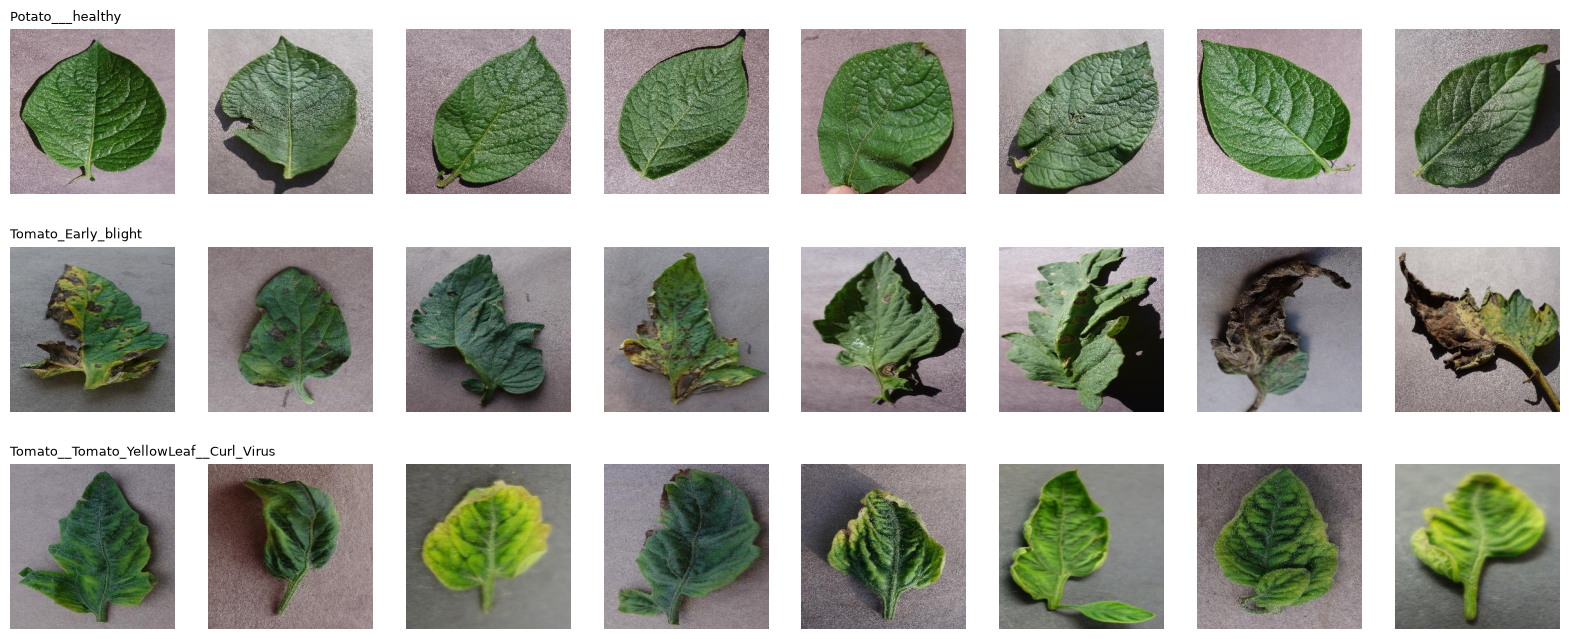

In [11]:
print([f for f in raiz.rglob("*") if f.is_file() and f.suffix.lower() != ".jpg"]) # pega todos os arquivos que não terminam em .jpg

# Classes do dataset escolhidas a dedo
classes_vistas = ("Potato___healthy", # a de menor quantidade
                  "Tomato_Early_blight", # doença com manchas visíveis, para ver se é difícil distinguir uma folha saudável de uma doente
                  "Tomato__Tomato_YellowLeaf__Curl_Virus" # a de maior quantidade
)

for classe in classes_vistas:
    print(classe, sorted(f.name for f in (raiz / classe).iterdir())[:4]) # pega os 4 primeiros arquivos de cada pasta das classes selecionadas

# Plotando as imagens das folhas das classes 
fig, eixos = plt.subplots(3, 8, figsize=(20, 8))  
for linha, classe in zip(eixos, classes_vistas):  
    jpgs = sorted(f for f in (raiz / classe).iterdir() if f.suffix.lower() == ".jpg")
    for ax, c in zip(linha, random.sample(jpgs, 8)):
        ax.imshow(mpimg.imread(c))
        ax.axis("off")
    linha[0].set_title(classe, loc="left", fontsize=9)
plt.show()

In [12]:
# Funções para extração de metadados do nome dos arquivos, sendo importantes para não fazer o sorteio de imagens para treino e validação com fotos parecidas umas com as outras 
def chave(nome):
    return nome.split("___", 1)[-1].rsplit(".", 1)[0]

def numero(f):
    m = re.search(r"(\d+)\.[^.]+$", f.name)
    return int(m.group(1)) if m else -1

Potato___healthy 152 arquivos | 152 nomes originais distintos
Tomato_Early_blight 1000 arquivos | 1000 nomes originais distintos
Tomato_Late_blight 1909 arquivos | 1901 nomes originais distintos


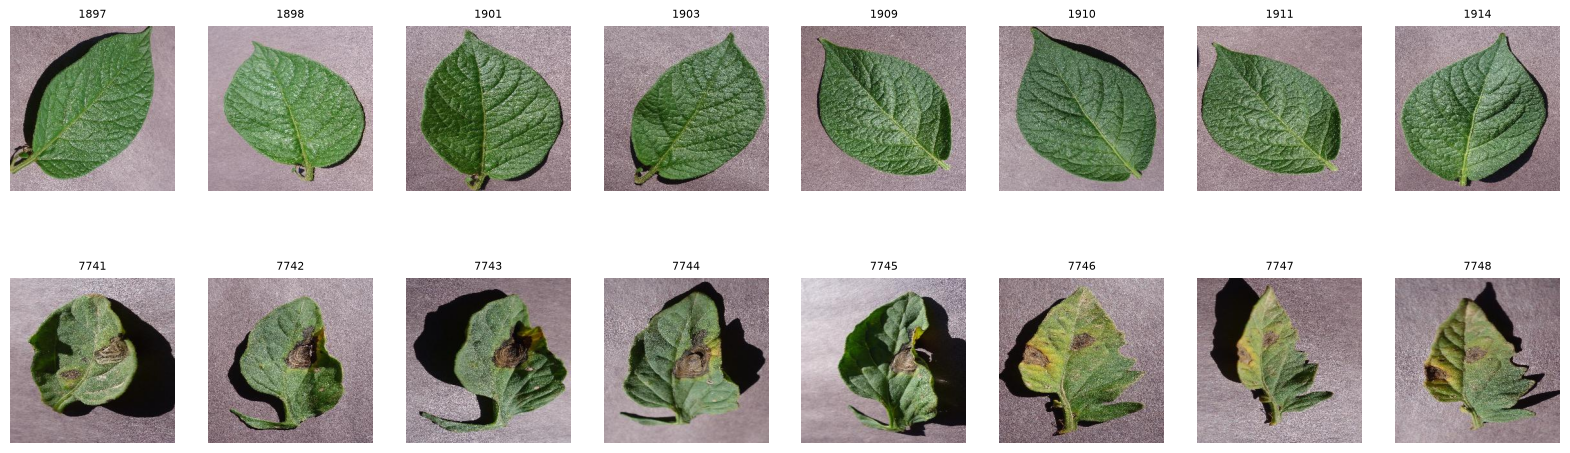

In [13]:
# Teste da suspeita que o dataset possui imagens repetidas ou quase idênticas, que inflariam a validação
# Compara quantos arquivos existem com a quantidade de nomes distintos, mostrando 8 fotos de números consecutivos pra ver se parecem a mesma folha

# Pegando os nomes distintos
for classe in ("Potato___healthy", "Tomato_Early_blight", "Tomato_Late_blight"): 
    arqs = [f for f in (raiz / classe).iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png")]
    chaves = Counter(chave(f.name) for f in arqs)
    print(classe, len(arqs), "arquivos |", len(chaves), "nomes originais distintos")

# Plotando as imagens
fig, eixos = plt.subplots(2, 8, figsize=(20, 6))
for linha, classe in zip(eixos, ("Potato___healthy", "Tomato_Early_blight")):
    arqs = sorted((f for f in (raiz / classe).iterdir() if f.suffix.lower() == ".jpg"), key=numero)
    meio = len(arqs) // 2
    for ax, f in zip(linha, arqs[meio:meio + 8]):
        ax.imshow(mpimg.imread(f))
        ax.set_title(str(numero(f)), fontsize=8)
        ax.axis("off")
plt.show()

In [14]:
# Descobrindo de onde as fotos de cada classe vêm
# O nome do arquivo tem um código antes do número que identifica a fonte ou a sessão de fotografia 
# Conta quantas fotos de cada código existem
def prefixo(nome):
    original = nome.split("___", 1)[-1]
    return original.rsplit(" ", 1)[0]

for pasta in sorted(raiz.iterdir()):
    if pasta.is_dir():
        c = Counter(prefixo(f.name) for f in pasta.iterdir()
                    if f.suffix.lower() in (".jpg", ".jpeg", ".png"))
        print(pasta.name, dict(c.most_common(4)))

Pepper__bell___Bacterial_spot {'JR_B.Spot': 589, 'NREC_B.Spot': 408}
Pepper__bell___healthy {'JR_HL': 1476, 'bell-pepper-plant-61726.jpg': 1, 'Screen Shot 2015-05-06 at 4.01.13': 1}
Potato___Early_blight {'RS_Early.B': 1000}
Potato___healthy {'RS_HL': 152}
Potato___Late_blight {'RS_LB': 1000}
Tomato__Target_Spot {'Com.G_TgS_FL': 1404}
Tomato__Tomato_mosaic_virus {'PSU_CG': 373}
Tomato__Tomato_YellowLeaf__Curl_Virus {'UF.GRC_YLCV_Lab': 1571, 'YLCV_GCREC': 880, 'YLCV_NREC': 757}
Tomato_Bacterial_spot {'GCREC_Bact.Sp': 1756, 'UF.GRC_BS_Lab Leaf': 371}
Tomato_Early_blight {'RS_Erly.B': 1000}
Tomato_healthy {'RS_HL': 999, 'GH_HL Leaf': 590, 'CG1.JPG': 1, '2700323949_95aa2eaa01_o.jpg': 1}
Tomato_Late_blight {'RS_Late.B': 920, 'GHLB2 Leaf': 744, 'GHLB2ES Leaf': 27, 'GHLB_PS Leaf 1 Day': 6}
Tomato_Leaf_Mold {'Crnl_L.Mold': 952}
Tomato_Septoria_leaf_spot {'Matt.S_CG': 1000, 'JR_Sept.L.S': 497, 'Keller.St_CG': 274}
Tomato_Spider_mites_Two_spotted_spider_mite {'Com.G_SpM_FL': 1676}


In [15]:
# Medida de quanto o fundo da foto muda de uma fonte para a outra
# Se cada fonte tiver um tom de fundo diferente, o modelo poderia aprender o fundo em vez da doença
# A função reduz uma imagem a 3 números (cor média da borda em RGB), e com isso dá para comparar fontes e classes
def cor_borda(caminho, n=12):
    img = np.asarray(tf.keras.utils.load_img(caminho, target_size=(128, 128)), dtype=float)
    faixas = [img[:n], img[-n:], img[:, :n], img[:, -n:]]
    return np.concatenate([f.reshape(-1, 3) for f in faixas]).mean(axis=0)

In [16]:
# Gerando a tabela que mostrou que o fundo muda com a fonte da foto
# Pra cada código fonte, ela sorteia 20 fotos, mede a cor média da borda de cada uma e tira a média das 20 
random.seed(0)
for pasta in sorted(raiz.iterdir()):
    if not pasta.is_dir():
        continue
    por_codigo = {}
    for f in sorted(pasta.iterdir()):
        if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
            por_codigo.setdefault(prefixo(f.name), []).append(f)
    for codigo, arqs in por_codigo.items():
        if len(arqs) >= 20:
            amostra = random.sample(arqs, 20)
            media = np.mean([cor_borda(f) for f in amostra], axis=0)
            print(f"{pasta.name[:30]:30s} {codigo[:16]:16s} {media.round(0)}")

Pepper__bell___Bacterial_spot  JR_B.Spot        [150. 141. 144.]
Pepper__bell___Bacterial_spot  NREC_B.Spot      [144. 134. 131.]
Pepper__bell___healthy         JR_HL            [163. 155. 157.]
Potato___Early_blight          RS_Early.B       [147. 145. 147.]
Potato___healthy               RS_HL            [154. 140. 143.]
Potato___Late_blight           RS_LB            [140. 131. 135.]
Tomato__Target_Spot            Com.G_TgS_FL     [140. 129. 135.]
Tomato__Tomato_mosaic_virus    PSU_CG           [138. 124. 141.]
Tomato__Tomato_YellowLeaf__Cur YLCV_NREC        [145. 130. 128.]
Tomato__Tomato_YellowLeaf__Cur YLCV_GCREC       [136. 126. 124.]
Tomato__Tomato_YellowLeaf__Cur UF.GRC_YLCV_Lab  [125. 127. 120.]
Tomato_Bacterial_spot          GCREC_Bact.Sp    [131. 124. 121.]
Tomato_Bacterial_spot          UF.GRC_BS_Lab Le [119. 120. 117.]
Tomato_Early_blight            RS_Erly.B        [138. 132. 134.]
Tomato_healthy                 GH_HL Leaf       [110. 110. 114.]
Tomato_healthy           

In [17]:
# Teste para saber se apenas o fundo da imagem consegue entregar informações úteis para a previsão do modelo
# Se vamos utilizar o fundo, vamos procurar mais informações dele, ao invés de retornar um vetor de 3 números, vai ser utilizado um vetor de 12, sendo 3 números para cada borda da imagem
def feats_borda(caminho, n=12):
    img = np.asarray(tf.keras.utils.load_img(caminho, target_size=(128, 128)), dtype=float)
    faixas = [img[:n], img[-n:], img[:, :n], img[:, -n:]]
    return np.concatenate([f.reshape(-1, 3).mean(axis=0) for f in faixas])

In [18]:
# Preparando os dados teste do atalho do fundo
# Transforma as fotos em uma tabela de 12 números com o rótulo da classe, já separada em treino e teste
Xtr, ytr, Xte, yte = [], [], [], []
for pasta in sorted(raiz.iterdir()):
    if not pasta.is_dir():
        continue
    por_codigo = {}
    for f in pasta.iterdir():
        if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
            por_codigo.setdefault(prefixo(f.name), []).append(f)
    for codigo, arqs in por_codigo.items():
        if len(arqs) < 20:
            continue
        arqs = sorted(arqs, key=numero)
        idx = np.linspace(0, len(arqs) - 1, min(120, len(arqs))).astype(int)
        escolhidos = [arqs[i] for i in idx]
        corte = int(len(escolhidos) * 0.7)
        for k, f in enumerate(escolhidos):
            if k < corte:
                Xtr.append(feats_borda(f)); ytr.append(pasta.name)
            else:
                Xte.append(feats_borda(f)); yte.append(pasta.name)

In [19]:
# Onde o teste do atalho acontece
# Treina um classificar simples que só vê 12 números do fundo, mede quanto ele acerta no que não viu, e compara com dois chutes
fundo = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xtr, ytr)
prev = fundo.predict(Xte)
print("acurácia só com a cor da borda:", round(accuracy_score(yte, prev), 2))
print("F1 macro:", round(f1_score(yte, prev, average="macro"), 2))
print("chute na classe mais comum:", round(Counter(yte).most_common(1)[0][1] / len(yte), 2),
      "| chute aleatório entre 15 classes:", round(1 / 15, 2))

acurácia só com a cor da borda: 0.38
F1 macro: 0.3
chute na classe mais comum: 0.13 | chute aleatório entre 15 classes: 0.07


In [20]:
# Prepara a divisão do dataset em treino, validação e teste
# Define onde as pastas serão criadas, o tamanho de cada bloco de fotos e a seed do sorteio
destino = Path("data/dividido")
TAM_BLOCO = 10
random.seed(42)

def copiar(arquivos, pasta):
    pasta.mkdir(parents=True, exist_ok=True)
    for f in arquivos:
        shutil.copy(f, pasta / f.name)

In [21]:
# Divisão do dataset em treino (70%), validação (15%) e teste (15%)
# Problema: o dataset não vem dividido, e fotos vizinhas se parecem muito, então um sorteio por foto poria vizinhas dos dois lados e inflaria a validação
# Solução: divide as imagens em blocos de 10 fotos consecutivas, sorteando os blocos, e fazendo isso dentro de cada fonte, pra todas as fontes aparecem nas três partes
resumo = Counter()
for pasta in sorted(raiz.iterdir()):
    if not pasta.is_dir():
        continue
    por_codigo = {}
    for f in pasta.iterdir():
        if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
            por_codigo.setdefault(prefixo(f.name), []).append(f)
    for codigo, arqs in por_codigo.items():
        if len(arqs) < 5:
            continue
        arqs = sorted(arqs, key=numero)
        blocos = [arqs[i:i + TAM_BLOCO] for i in range(0, len(arqs), TAM_BLOCO)]
        random.shuffle(blocos)
        n = len(blocos)
        if n < 3:
            partes = {"train": blocos}
        else:
            n_val = max(1, round(n * 0.15))
            n_teste = max(1, round(n * 0.15))
            partes = {"test": blocos[:n_teste],
                      "val": blocos[n_teste:n_teste + n_val],
                      "train": blocos[n_teste + n_val:]}
        for nome, lista in partes.items():
            imgs = [f for b in lista for f in b]
            copiar(imgs, destino / nome / pasta.name)
            resumo[(nome, pasta.name)] += len(imgs)

In [22]:
# Conferência da divisão
for nome in ("train", "val", "test"):
    print(nome, sum(v for (s, _), v in resumo.items() if s == nome))
print({c: resumo[("test", c)] for c in ("Potato___healthy", "Tomato_Early_blight")})

train 14324
val 3063
test 3055
{'Potato___healthy': 20, 'Tomato_Early_blight': 150}


In [23]:
# Criando os geradores que definem como as imagens serão tratadas no treinamento
# Um para treino e outra para validação
IMG = (160, 160)
BATCH = 32

gen_treino = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    horizontal_flip=True,
    vertical_flip=True,
    zoom_range=0.2,
    brightness_range=(0.7, 1.3),
)
gen_avalia = ImageDataGenerator(preprocessing_function=preprocess_input)

In [24]:
# Aplicando os geradores nas pastas de treino, validação e teste
treino = gen_treino.flow_from_directory(
    str(destino / "train"), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=True)
validacao = gen_avalia.flow_from_directory(
    str(destino / "val"), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=False)
teste = gen_avalia.flow_from_directory(
    str(destino / "test"), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=False)

Found 14324 images belonging to 15 classes.
Found 3063 images belonging to 15 classes.
Found 3055 images belonging to 15 classes.


In [25]:
# Calculando os pesos para cada classe para compensar o desbalanceamento do dataset
contagem = np.bincount(treino.classes)
pesos_cheios = {i: len(treino.classes) / (len(contagem) * c) for i, c in enumerate(contagem)}
pesos = {i: float(np.sqrt(p)) for i, p in pesos_cheios.items()}
for nome, i in treino.class_indices.items():
    print(f"{nome:45s} {contagem[i]:5d}  peso cheio {pesos_cheios[i]:.2f}  peso suave {pesos[i]:.2f}")

Pepper__bell___Bacterial_spot                   697  peso cheio 1.37  peso suave 1.17
Pepper__bell___healthy                         1036  peso cheio 0.92  peso suave 0.96
Potato___Early_blight                           700  peso cheio 1.36  peso suave 1.17
Potato___Late_blight                            700  peso cheio 1.36  peso suave 1.17
Potato___healthy                                112  peso cheio 8.53  peso suave 2.92
Tomato_Bacterial_spot                          1500  peso cheio 0.64  peso suave 0.80
Tomato_Early_blight                             700  peso cheio 1.36  peso suave 1.17
Tomato_Late_blight                             1200  peso cheio 0.80  peso suave 0.89
Tomato_Leaf_Mold                                672  peso cheio 1.42  peso suave 1.19
Tomato_Septoria_leaf_spot                      1231  peso cheio 0.78  peso suave 0.88
Tomato_Spider_mites_Two_spotted_spider_mite    1176  peso cheio 0.81  peso suave 0.90
Tomato__Target_Spot                             990  p

In [26]:
# Definindo um callback, um bloco de código que o Keras chama automaticamento nos treinamentos
# Calcula o F1 macro na avaliação e salva o modelo em disco quando o F1 melhora
class MelhorF1(tf.keras.callbacks.Callback):
    def __init__(self, gerador, caminho):
        super().__init__()
        self.gerador, self.caminho, self.melhor = gerador, caminho, -1

    def on_epoch_end(self, epoch, logs=None):
        self.gerador.reset()
        prob = self.model.predict(self.gerador, verbose=0)
        f1 = f1_score(self.gerador.classes, prob.argmax(axis=1), average="macro")
        print(f"  val_f1_macro: {f1:.4f}")
        if f1 > self.melhor:
            self.melhor = f1
            self.model.save(self.caminho)

Path("modelos").mkdir(exist_ok=True)

In [27]:
# Definindo a base que vai ser utilizada para o treinamento do modelo
# Apenas a última camada poderá ser treinável
base = MobileNetV2(input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False

modelo = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(len(treino.class_indices), activation="softmax"),
])
modelo.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [ ]:
# Treinando o modelo
inicio = time.time()
hist1 = modelo.fit(
    treino, validation_data=validacao, epochs=5,
    class_weight=pesos, callbacks=[MelhorF1(validacao, "modelos/fase1.keras")],
)
print(f"Tempo total: {(time.time() - inicio) / 60:.1f} min")

Epoch 1/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 715ms/step - accuracy: 0.6631 - loss: 1.0373  val_f1_macro: 0.7801
448/448 ━━━━━━━━━━━━━━━━━━━━ 406s 901ms/step - accuracy: 0.6631 - loss: 1.0373 - val_accuracy: 0.8155 - val_loss: 0.5969
Epoch 2/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step - accuracy: 0.8102 - loss: 0.5739  val_f1_macro: 0.8034
448/448 ━━━━━━━━━━━━━━━━━━━━ 222s 496ms/step - accuracy: 0.8102 - loss: 0.5739 - val_accuracy: 0.8293 - val_loss: 0.5336
Epoch 3/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step - accuracy: 0.8321 - loss: 0.4995  val_f1_macro: 0.8308
448/448 ━━━━━━━━━━━━━━━━━━━━ 266s 594ms/step - accuracy: 0.8321 - loss: 0.4995 - val_accuracy: 0.8488 - val_loss: 0.4621
Epoch 4/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - accuracy: 0.8392 - loss: 0.4746  val_f1_macro: 0.8176
448/448 ━━━━━━━━━━━━━━━━━━━━ 233s 519ms/step - accuracy: 0.8392 - loss: 0.4746 - val_accuracy: 0.8472 - val_loss: 0.4576
Epoch 5/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step - accuracy: 0.8528 - loss: 

In [28]:
# Avaliação da fase 1, classe por classe
modelo_f1 = tf.keras.models.load_model("modelos/fase1.keras")

validacao.reset()
prob_v = modelo_f1.predict(validacao)
real_v = validacao.classes
prev_v = prob_v.argmax(axis=1)
nomes = list(validacao.class_indices)

print(classification_report(real_v, prev_v, target_names=nomes, digits=2))

96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 658ms/step
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.86      0.97      0.92       150
                     Pepper__bell___healthy       0.96      1.00      0.98       220
                      Potato___Early_blight       0.94      0.87      0.90       150
                       Potato___Late_blight       0.88      0.75      0.81       150
                           Potato___healthy       0.77      0.85      0.81        20
                      Tomato_Bacterial_spot       0.89      0.85      0.87       316
                        Tomato_Early_blight       0.86      0.34      0.49       150
                         Tomato_Late_blight       0.78      0.85      0.81       257
                           Tomato_Leaf_Mold       0.82      0.89      0.85       140
                  Tomato_Septoria_leaf_spot       0.74      0.87      0.80       270
Tomato_Spider_mites_Tw

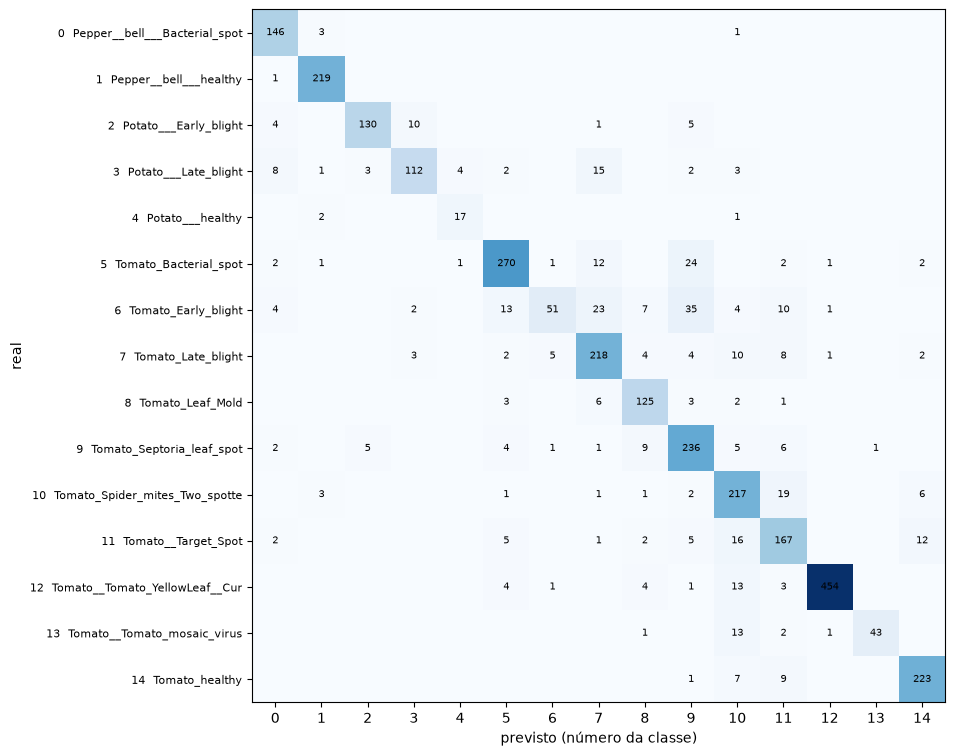

In [29]:
# Matriz de confusão do modelo
cm = confusion_matrix(real_v, prev_v)
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(nomes)))
ax.set_yticks(range(len(nomes)))
ax.set_xticklabels(range(len(nomes)))
ax.set_yticklabels([f"{i}  {n[:30]}" for i, n in enumerate(nomes)], fontsize=8)
for i in range(len(nomes)):
    for j in range(len(nomes)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
ax.set_xlabel("previsto (número da classe)")
ax.set_ylabel("real")
plt.show()

Early_blight acertadas: 51 | previstas como Septoria: 35


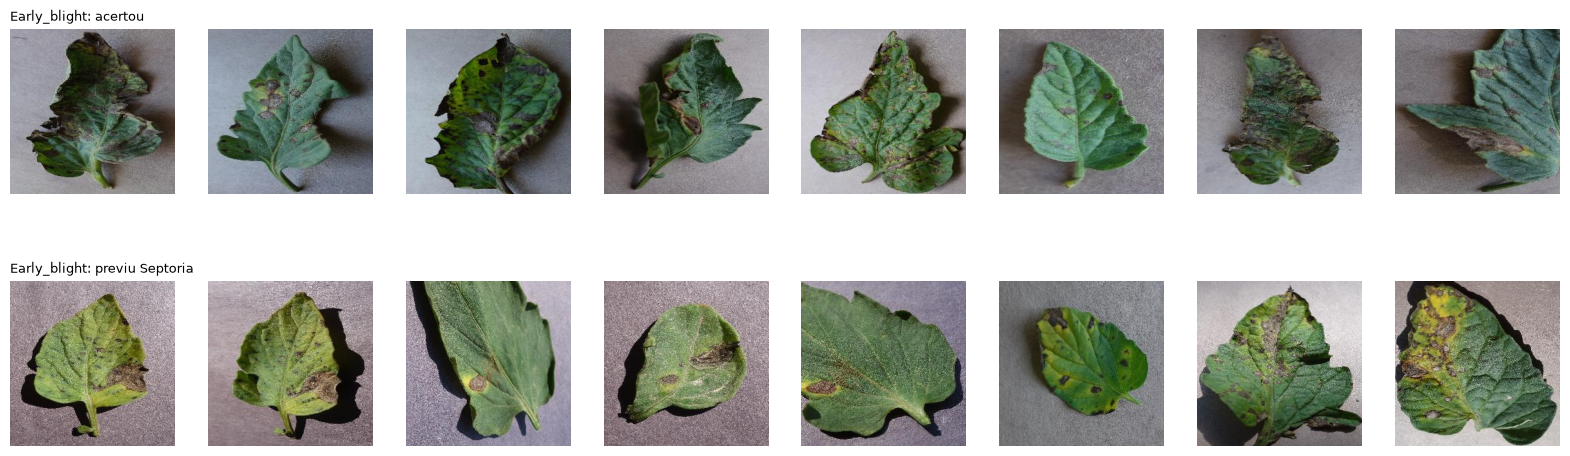

In [30]:
# Separa as imagens da classe em dois grupos, as que a fase 1 acertou e as que ela chamou de Septoria (destino mais comum dos erros)
# Mostra 8 de cada lado para comparação
i6 = nomes.index("Tomato_Early_blight")
i9 = nomes.index("Tomato_Septoria_leaf_spot")
caminhos_v = validacao.filepaths

certas = [i for i in range(len(real_v)) if real_v[i] == i6 and prev_v[i] == i6]
erradas = [i for i in range(len(real_v)) if real_v[i] == i6 and prev_v[i] == i9]
print("Early_blight acertadas:", len(certas), "| previstas como Septoria:", len(erradas))

random.seed(3)
fig, eixos = plt.subplots(2, 8, figsize=(20, 6))
for linha, grupo, titulo in zip(eixos, (certas, erradas),
                                ("Early_blight: acertou", "Early_blight: previu Septoria")):
    for ax, i in zip(linha, random.sample(grupo, 8)):
        ax.imshow(mpimg.imread(caminhos_v[i]))
        ax.axis("off")
    linha[0].set_title(titulo, loc="left", fontsize=9)
plt.show()

In [31]:
# Preparação do fine-tuning
# As últimas 30 camadas da base são liberadas ao invés de apenas a última para se ajustar ao seu problema
modelo_ft = tf.keras.models.load_model("modelos/fase1.keras")

base_ft = modelo_ft.layers[0]
base_ft.trainable = True
for camada in base_ft.layers[:-30]:
    camada.trainable = False
for camada in base_ft.layers[-30:]:
    if isinstance(camada, tf.keras.layers.BatchNormalization):
        camada.trainable = False

modelo_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

In [ ]:
# Treinamento do fine-tuning
inicio = time.time()
hist2 = modelo_ft.fit(
    treino, validation_data=validacao, epochs=5,
    class_weight=pesos, callbacks=[MelhorF1(validacao, "modelos/fase2.keras")],
)

print(f"Tempo total: {(time.time() - inicio) / 60:.1f} min")

Epoch 1/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 743ms/step - accuracy: 0.8723 - loss: 0.3782  val_f1_macro: 0.8638
448/448 ━━━━━━━━━━━━━━━━━━━━ 382s 845ms/step - accuracy: 0.8723 - loss: 0.3782 - val_accuracy: 0.8812 - val_loss: 0.3578
Epoch 2/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.8836 - loss: 0.3356  val_f1_macro: 0.8590
448/448 ━━━━━━━━━━━━━━━━━━━━ 259s 578ms/step - accuracy: 0.8836 - loss: 0.3356 - val_accuracy: 0.8812 - val_loss: 0.3601
Epoch 3/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 551ms/step - accuracy: 0.8974 - loss: 0.3066  val_f1_macro: 0.8785
448/448 ━━━━━━━━━━━━━━━━━━━━ 304s 678ms/step - accuracy: 0.8974 - loss: 0.3066 - val_accuracy: 0.8932 - val_loss: 0.3226
Epoch 4/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 580ms/step - accuracy: 0.9040 - loss: 0.2746  val_f1_macro: 0.8881
448/448 ━━━━━━━━━━━━━━━━━━━━ 316s 706ms/step - accuracy: 0.9040 - loss: 0.2746 - val_accuracy: 0.9017 - val_loss: 0.2992
Epoch 5/5
448/448 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.9129 - loss: 

In [ ]:
# Comparando a fase 1 e 2 classe por classe
modelo_f2 = tf.keras.models.load_model("modelos/fase2.keras")
validacao.reset()
prev_2 = modelo_f2.predict(validacao).argmax(axis=1)

idx = list(range(len(nomes)))
p1, r1, f1_1, _ = precision_recall_fscore_support(real_v, prev_v, labels=idx, zero_division=0)
p2, r2, f1_2, _ = precision_recall_fscore_support(real_v, prev_2, labels=idx, zero_division=0)

for i, n in enumerate(nomes):
    print(f"{n[:40]:40s} F1 {f1_1[i]:.2f} -> {f1_2[i]:.2f} | recall {r1[i]:.2f} -> {r2[i]:.2f} | precision {p1[i]:.2f} -> {p2[i]:.2f}")

print("F1 macro:", round(f1_1.mean(), 3), "->", round(f1_2.mean(), 3))
print("acurácia:", round((prev_v == real_v).mean(), 3), "->", round((prev_2 == real_v).mean(), 3))

96/96 ━━━━━━━━━━━━━━━━━━━━ 19s 191ms/step
Pepper__bell___Bacterial_spot            F1 0.92 -> 0.96 | recall 0.97 -> 0.99 | precision 0.86 -> 0.92
Pepper__bell___healthy                   F1 0.98 -> 0.99 | recall 1.00 -> 1.00 | precision 0.96 -> 0.99
Potato___Early_blight                    F1 0.90 -> 0.93 | recall 0.87 -> 0.91 | precision 0.94 -> 0.94
Potato___Late_blight                     F1 0.81 -> 0.87 | recall 0.75 -> 0.83 | precision 0.88 -> 0.91
Potato___healthy                         F1 0.81 -> 0.86 | recall 0.85 -> 0.90 | precision 0.77 -> 0.82
Tomato_Bacterial_spot                    F1 0.87 -> 0.91 | recall 0.85 -> 0.85 | precision 0.89 -> 0.97
Tomato_Early_blight                      F1 0.49 -> 0.70 | recall 0.34 -> 0.59 | precision 0.86 -> 0.84
Tomato_Late_blight                       F1 0.81 -> 0.84 | recall 0.85 -> 0.87 | precision 0.78 -> 0.81
Tomato_Leaf_Mold                         F1 0.85 -> 0.91 | recall 0.89 -> 0.94 | precision 0.82 -> 0.89
Tomato_Septoria_leaf_s

In [ ]:
# Decide qual versão do modelo vai pro teste 
validacao.reset()
prob_2 = modelo_f2.predict(validacao)
w = np.array([pesos[i] for i in range(len(nomes))])
prev_2aj = (prob_2 / w).argmax(axis=1)

for rotulo, prev in (("normal", prev_2), ("ajustada", prev_2aj)):
    print(rotulo, "| F1 macro:", round(f1_score(real_v, prev, average="macro"), 3),
          "| acurácia:", round((prev == real_v).mean(), 3))

96/96 ━━━━━━━━━━━━━━━━━━━━ 19s 202ms/step
normal | F1 macro: 0.888 | acurácia: 0.902
ajustada | F1 macro: 0.893 | acurácia: 0.905


In [ ]:
# Investigan os erros da fase 2: "olha pra X pra saber se Y"
i_mos = nomes.index("Tomato__Tomato_mosaic_virus")
i_eb = nomes.index("Tomato_Early_blight")
falsos_mosaico = Counter(nomes[r] for r, p in zip(real_v, prev_2) if p == i_mos and r != i_mos)
erros_eb = Counter(nomes[p] for r, p in zip(real_v, prev_2) if r == i_eb and p != i_eb)
print("falsos mosaico vieram de:", falsos_mosaico.most_common(4))
print("Early_blight errou para:", erros_eb.most_common(4))

falsos mosaico vieram de: [('Tomato_Septoria_leaf_spot', 6), ('Tomato__Tomato_YellowLeaf__Curl_Virus', 6), ('Tomato_Leaf_Mold', 3), ('Tomato_Early_blight', 2)]
Early_blight errou para: [('Tomato_Septoria_leaf_spot', 25), ('Tomato_Late_blight', 14), ('Tomato__Target_Spot', 6), ('Tomato_Bacterial_spot', 5)]


In [ ]:
# Teste final
usar_ajuste = False

teste.reset()
prob_t = modelo_f2.predict(teste)
real_t = teste.classes
nomes_t = list(teste.class_indices)

w = np.array([pesos[i] for i in range(len(nomes_t))])
prev_t = (prob_t / w if usar_ajuste else prob_t).argmax(axis=1)

print(classification_report(real_t, prev_t, target_names=nomes_t, digits=2))
print("F1 macro:", round(f1_score(real_t, prev_t, average="macro"), 3))

96/96 ━━━━━━━━━━━━━━━━━━━━ 48s 499ms/step
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.95      0.95      0.95       150
                     Pepper__bell___healthy       0.96      1.00      0.98       220
                      Potato___Early_blight       1.00      0.96      0.98       150
                       Potato___Late_blight       0.96      0.81      0.88       150
                           Potato___healthy       0.57      1.00      0.73        20
                      Tomato_Bacterial_spot       0.92      0.91      0.91       311
                        Tomato_Early_blight       0.84      0.55      0.67       150
                         Tomato_Late_blight       0.83      0.93      0.88       260
                           Tomato_Leaf_Mold       0.82      0.85      0.84       140
                  Tomato_Septoria_leaf_spot       0.87      0.86      0.86       270
Tomato_Spider_mites_Tw

In [50]:
def classificar_folha(caminho, n=3):
    img = tf.keras.utils.load_img(caminho, target_size=IMG)
    x = preprocess_input(tf.keras.utils.img_to_array(img)[np.newaxis])
    p = modelo_f2.predict(x, verbose=0)[0]
    top = p.argsort()[::-1][:n]
    return [(nomes_t[i], round(float(p[i]), 2)) for i in top]

In [51]:
folhas = {
    "folha1":  ("fotos_campo/folha1.png",  "Tomato_healthy",         "uma folha recortada, fundo liso"),
    "folha2":  ("fotos_campo/folha2.png",  "Tomato_healthy",         "folhas na mão, fundo de terra"),
    "folha3":  ("fotos_campo/folha3.png",  "Tomato_healthy",         "ramo, fundo de serragem"),
    "folha4":  ("fotos_campo/folha4.png",  "doente, não sei qual",   "uma folha, manchas amarelas"),
    "folha5":  ("fotos_campo/folha5.png",  "Pepper__bell___healthy", "uma folha recortada, fundo liso"),
    "folha6":  ("fotos_campo/folha6.png",  "Pepper__bell___healthy", "planta no chão (cultura incerta)"),
    "folha7":  ("fotos_campo/folha7.png",  "Pepper__bell___healthy", "uma folha na mão, fundo de janela"),
    "folha8":  ("fotos_campo/folha8.png",  "Pepper__bell___healthy", "muda em vaso"),
    "folha9":  ("fotos_campo/folha9.png",  "fora do modelo?",        "batata-doce?, fundo escuro"),
    "folha10": ("fotos_campo/folha10.png", "fora do modelo?",        "batata-doce?, recortada"),
    "folha11": ("fotos_campo/folha11.png", "fora do modelo?",        "batata-doce?, cascalho"),
    "folha12": ("fotos_campo/folha12.png", "Potato___healthy",       "várias folhas, fundo de terra"),
}

In [52]:
modelo_f2 = tf.keras.models.load_model("modelos/fase2.keras")
nomes_t = list(teste.class_indices)
print(len(nomes_t), "classes |", nomes_t[:3])

15 classes | ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight']


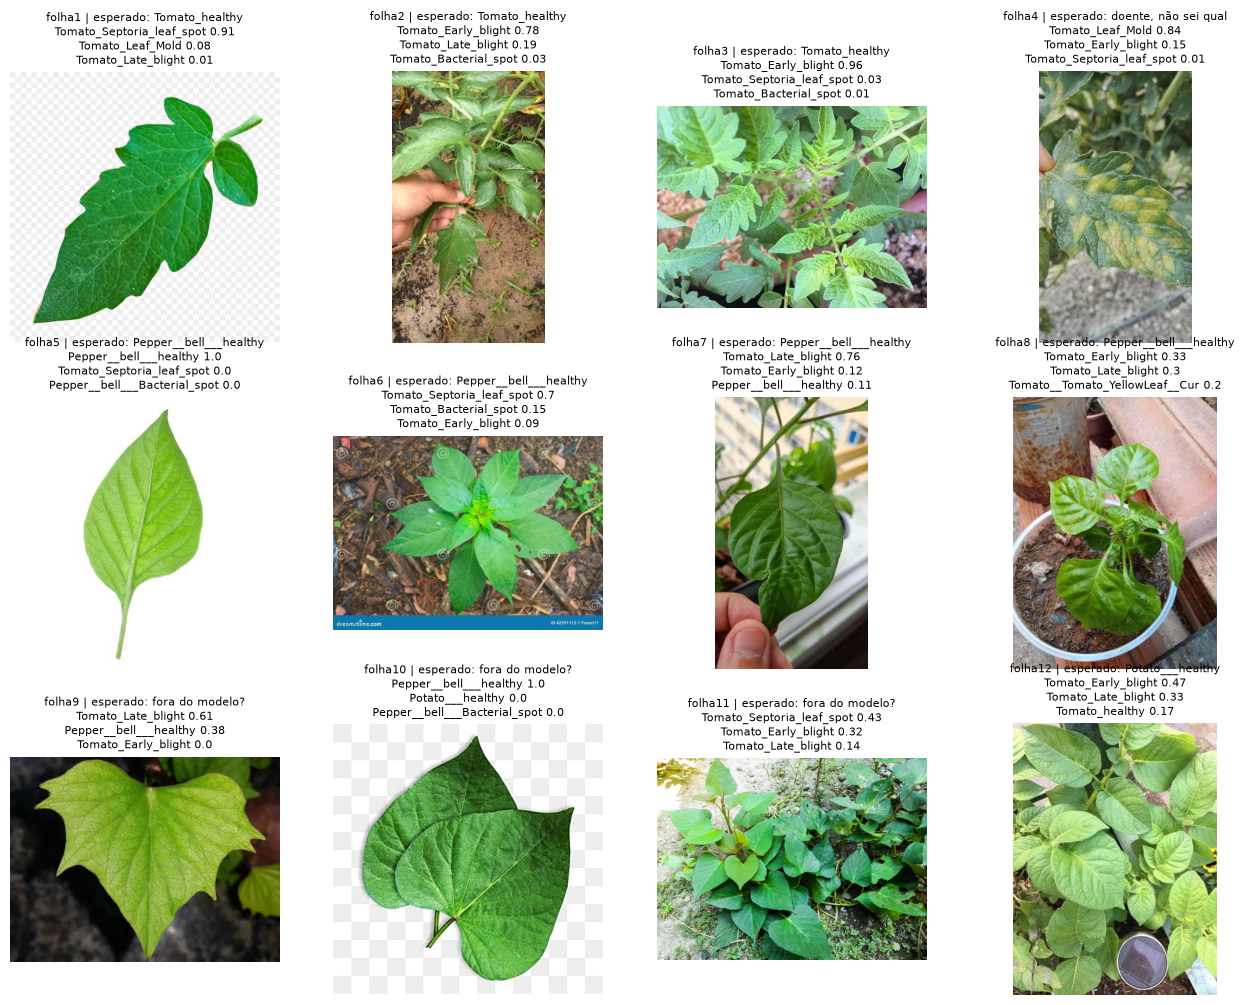

In [53]:
fig, eixos = plt.subplots(3, 4, figsize=(16, 12))
for ax, (nome, (caminho, esperado, obs)) in zip(eixos.flat, folhas.items()):
    top = classificar_folha(caminho)
    ax.imshow(mpimg.imread(caminho))
    ax.set_title(f"{nome} | esperado: {esperado}\n" +
                 "\n".join(f"{n[:30]} {p}" for n, p in top), fontsize=8)
    ax.axis("off")
plt.show()

In [55]:
x = np.random.default_rng(0).random((1, 160, 160, 3)).astype("float32")
m = tf.keras.models.load_model("modelos/fase2.keras")
print("saida pra conferir:", m.predict(x, verbose=0)[0][:5])

saida pra conferir: [8.2113424e-08 1.6320619e-06 4.4260873e-05 4.5889905e-09 2.4795133e-07]


In [56]:
print(list(treino.class_indices))

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
